# Trabajo final: clasificación de puntaje crediticio

**Paola Andrea Tucuman Alarcon · Módulo FDL, Diplomado en Machine Learning (UPB)**

## Pregunta

¿Qué tan bien clasifican una red neuronal, KNN y Random Forest los registros crediticios de **clientes no vistos**? El archivo tiene varias observaciones mensuales por cliente, así que la prueba separa clientes completos. Las clases están codificadas como 0, 1 y 2; la fuente no documenta qué significa cada código.

El docente proporcionó el [CSV usado en el módulo](https://github.com/delveeducation/datasets/blob/main/credit_score.csv). El notebook permite leer una copia local o consultar ese enlace. El CSV no forma parte de esta carpeta.

## Paso 1. Importar herramientas

**Parte A · Preparación de datos.**

Uso Pandas para preparar datos, scikit-learn para las particiones y dos modelos, TensorFlow/Keras para la red neuronal y Matplotlib para los gráficos.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

## Paso 2. Cargar el CSV

Si existe `data/credit_score.csv`, uso esa copia. La variable de entorno `CREDIT_SCORE_CSV` permite indicar otra ruta local. Si no hay archivo local, se consulta el enlace que figura en mi entrega original.

In [2]:
source_url = "https://raw.githubusercontent.com/delveeducation/datasets/refs/heads/main/credit_score.csv"
local_path = Path(os.environ.get("CREDIT_SCORE_CSV", "data/credit_score.csv"))
source = local_path if local_path.is_file() else source_url
data = pd.read_csv(source)
print(f"Registros: {len(data):,} · Columnas: {data.shape[1]}")

Registros: 96,696 · Columnas: 28


## Paso 3. Inspeccionar estructura y valores faltantes

El archivo incluye ocho meses por cliente. Solo muestro dimensiones, clases y faltantes; los campos `name` y `ssn` no intervienen en el análisis. Esta copia del CSV no tiene faltantes en las variables que utilizaré, así que no es necesario rellenar con la media.

In [3]:
print(f"Clientes: {data['customer_id'].nunique():,}")
print("Meses por cliente:", data.groupby("customer_id").size().value_counts().to_dict())
print("Clases:", data["credit_score"].value_counts().sort_index().to_dict())

Clientes: 12,087
Meses por cliente: {8: 12087}
Clases: {0: 27485, 1: 51503, 2: 17708}


## Paso 4. Seleccionar variables y etiqueta

Conservo las 13 variables numéricas elegidas en mi trabajo. `customer_id` se guarda **solo para dividir** los datos; no se entrega a los modelos como predictor.

In [4]:
relevant_features = [
    "age", "annual_income", "monthly_inhand_salary", "total_emi_per_month",
    "num_bank_accounts", "num_credit_card", "interest_rate", "num_of_loan",
    "num_of_delayed_payment", "outstanding_debt", "credit_utilization_ratio",
    "amount_invested_monthly", "monthly_balance",
]
target = "credit_score"
required = relevant_features + [target, "customer_id"]
missing_columns = set(required) - set(data.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas: {sorted(missing_columns)}")
if data[required].isna().any().any():
    raise ValueError("Hay valores faltantes en las columnas del análisis")
X = data[relevant_features]
y = data[target]
groups = data["customer_id"]
print(f"Variables predictoras: {len(relevant_features)} · Clases: {sorted(y.unique())}")
display(X.head(3))

Variables predictoras: 13 · Clases: [np.int64(0), np.int64(1), np.int64(2)]


age,annual_income,monthly_inhand_salary,total_emi_per_month,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,num_of_delayed_payment,outstanding_debt,credit_utilization_ratio,amount_invested_monthly,monthly_balance
23,19114.12,1824.8434,49.574947,3,4,3,4,7,809.98,26.822620,80.415300,312.49408
23,19114.12,1824.8434,49.574947,3,4,3,4,7,809.98,31.944960,118.280220,284.62915
23,19114.12,1824.8434,49.574947,3,4,3,4,7,809.98,28.609352,81.699524,331.20987


## Paso 5. Separar entrenamiento y prueba por cliente

Reservo el 20 % de los clientes para la prueba final (`random_state=42`). Compruebo que ningún identificador de cliente esté en ambos conjuntos.

In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
shared_customers = len(set(groups_train) & set(groups_test))
assert shared_customers == 0
print(f"Entrenamiento: {len(X_train):,} filas · Prueba: {len(X_test):,} filas")
print(f"Clientes compartidos: {shared_customers}")

Entrenamiento: 77,352 filas · Prueba: 19,344 filas
Clientes compartidos: 0


## Paso 6. Separar validación para la red neuronal

La red necesita una validación durante el entrenamiento. La tomo únicamente del conjunto de entrenamiento y también separo clientes completos. Así, la prueba final no guía los epochs ni la selección de pesos.

In [6]:
validation_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=43)
fit_idx, val_idx = next(
    validation_splitter.split(X_train, y_train, groups=groups_train)
)
X_nn_train, X_nn_val = X_train.iloc[fit_idx], X_train.iloc[val_idx]
y_nn_train, y_nn_val = y_train.iloc[fit_idx], y_train.iloc[val_idx]
assert not set(groups_train.iloc[fit_idx]) & set(groups_train.iloc[val_idx])
print(f"Red neuronal: {len(X_nn_train):,} filas para ajustar y {len(X_nn_val):,} para validar")

Red neuronal: 61,880 filas para ajustar y 15,472 para validar


## Paso 7. Normalizar para la red neuronal

Ajusto `StandardScaler` solo con el subconjunto que entrena la red. Después transformo validación y prueba con esa misma escala.

In [7]:
scaler_nn = StandardScaler()
X_nn_train_scaled = scaler_nn.fit_transform(X_nn_train)
X_nn_val_scaled = scaler_nn.transform(X_nn_val)
X_nn_test_scaled = scaler_nn.transform(X_test)
print("Forma de entrada de la red:", X_nn_train_scaled.shape)

Forma de entrada de la red: (61880, 13)


## Paso 8. Construir la red neuronal

**Parte B · Red neuronal.**

Conservo la arquitectura de mi entrega: capas densas de 128, 64 y 32 neuronas, dos capas de dropout de 0,3 y una salida `softmax` de tres clases.

In [8]:
model = Sequential([
    Input(shape=(X_nn_train_scaled.shape[1],)),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(3, activation="softmax"),
])
model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼─────────────────────

## Paso 9. Compilar y entrenar la red

Mantengo `Adam` y la pérdida `sparse_categorical_crossentropy` del original. `EarlyStopping` usa únicamente la validación, restaura los mejores pesos y evita usar la prueba para decidir cuándo terminar.

In [9]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
early_stopping = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
history = model.fit(
    X_nn_train_scaled, y_nn_train,
    epochs=100, batch_size=32,
    validation_data=(X_nn_val_scaled, y_nn_val),
    callbacks=[early_stopping], verbose=0,
)
print(f"Épocas ejecutadas: {len(history.history['loss'])}")

Épocas ejecutadas: 11


## Paso 10. Revisar la pérdida durante el entrenamiento

El gráfico conserva la comparación entre pérdida de entrenamiento y validación que había en mi notebook.

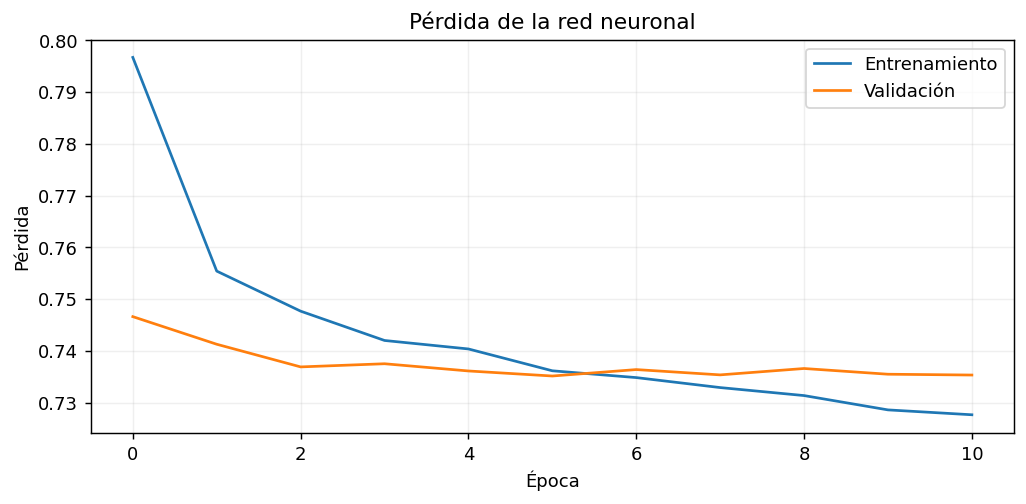

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.history["loss"], label="Entrenamiento")
ax.plot(history.history["val_loss"], label="Validación")
ax.set(title="Pérdida de la red neuronal", xlabel="Época", ylabel="Pérdida")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Paso 11. Evaluar la red con la prueba reservada

La prueba reservada se usa aquí para evaluar la red; no participó en el entrenamiento ni en la elección de la época final. La métrica describe este archivo y esta partición; no es una garantía para solicitudes crediticias reales.

In [11]:
loss_nn, accuracy_nn = model.evaluate(X_nn_test_scaled, y_test, verbose=0)
probabilities_nn = model.predict(X_nn_test_scaled, verbose=0)
prediction_nn = np.argmax(probabilities_nn, axis=1)
print(f"Red neuronal · pérdida: {loss_nn:.4f} · exactitud: {accuracy_nn:.4f}")

Red neuronal · pérdida: 0.7414 · exactitud: 0.6514


## Paso 12. Normalizar para KNN

**Parte C · Comparación con dos modelos supervisados.**

KNN depende de distancias entre observaciones. Ajusto un segundo escalador con **todo** el conjunto de entrenamiento, porque este modelo no usa la validación interna de la red.

In [12]:
scaler_knn = StandardScaler()
X_train_scaled = scaler_knn.fit_transform(X_train)
X_test_scaled = scaler_knn.transform(X_test)

## Paso 13. Entrenar y evaluar KNN

Conservo `n_neighbors=5` de mi entrega y evalúo en los clientes reservados.

In [13]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
prediction_knn = knn.predict(X_test_scaled)
print(f"KNN · exactitud: {accuracy_score(y_test, prediction_knn):.4f}")

KNN · exactitud: 0.6007


## Paso 14. Entrenar y evaluar Random Forest

Conservo 100 árboles y `random_state=42`. Los árboles usan las variables originales; no necesitan el escalado de KNN.

In [14]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
prediction_rf = rf_model.predict(X_test)
print(f"Random Forest · exactitud: {accuracy_score(y_test, prediction_rf):.4f}")

Random Forest · exactitud: 0.6523


## Paso 15. Añadir una referencia sencilla

Un modelo que siempre responde con la clase mayoritaria ayuda a interpretar si los otros métodos aportan más que esa regla básica.

In [15]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
prediction_baseline = baseline.predict(X_test)
print(f"Clase mayoritaria · exactitud: {accuracy_score(y_test, prediction_baseline):.4f}")

Clase mayoritaria · exactitud: 0.5432


## Paso 16. Comparar las métricas

Además de exactitud, calculo exactitud balanceada y F1 macro. Estas métricas dan contexto cuando las tres clases tienen tamaños diferentes.

In [16]:
predictions = {
    "Clase mayoritaria": prediction_baseline,
    "KNN": prediction_knn,
    "Random Forest": prediction_rf,
    "Red neuronal": prediction_nn,
}
comparison = pd.DataFrame([
    {
        "Modelo": name,
        "Exactitud": accuracy_score(y_test, predicted),
        "Exactitud balanceada": balanced_accuracy_score(y_test, predicted),
        "F1 macro": f1_score(y_test, predicted, average="macro"),
    }
    for name, predicted in predictions.items()
])
display(comparison.round(4))

Modelo,Exactitud,Exactitud balanceada,F1 macro
Clase mayoritaria,0.5432,0.3333,0.2347
KNN,0.6007,0.5385,0.5442
Random Forest,0.6523,0.5969,0.6060
Red neuronal,0.6514,0.5865,0.6000


## Paso 17. Dibujar una comparación legible

El gráfico usa F1 macro en los mismos clientes de prueba para los cuatro métodos.

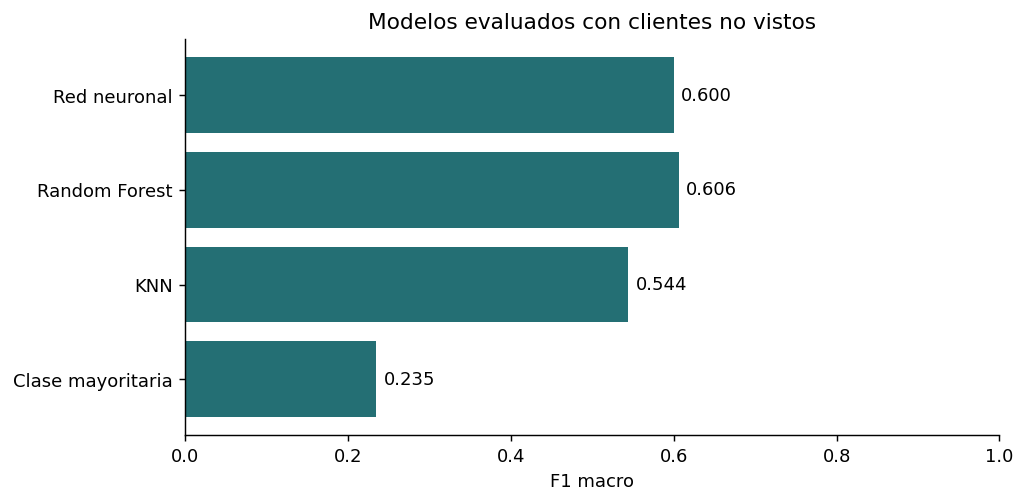

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(comparison["Modelo"], comparison["F1 macro"], color="#246f74")
ax.set(xlim=(0, 1), xlabel="F1 macro", title="Modelos evaluados con clientes no vistos")
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Paso 18. Comprobar por qué importa separar clientes

Como diagnóstico, repito Random Forest con una división aleatoria por filas. **No uso este valor como resultado principal:** esa división deja meses de los mismos clientes en entrenamiento y prueba.

In [18]:
row_train_idx, row_test_idx = train_test_split(
    np.arange(len(data)), test_size=0.2, random_state=42, stratify=y
)
shared_rows = len(set(groups.iloc[row_train_idx]) & set(groups.iloc[row_test_idx]))
rf_rows = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_rows.fit(X.iloc[row_train_idx], y.iloc[row_train_idx])
prediction_rows = rf_rows.predict(X.iloc[row_test_idx])
print(f"Clientes compartidos con división por filas: {shared_rows:,}")
print(f"Exactitud por filas (diagnóstico): {accuracy_score(y.iloc[row_test_idx], prediction_rows):.4f}")
print(f"Exactitud por clientes (resultado principal): {accuracy_score(y_test, prediction_rf):.4f}")

Clientes compartidos con división por filas: 10,037
Exactitud por filas (diagnóstico): 0.8051
Exactitud por clientes (resultado principal): 0.6523


## Conclusión y límites

Comparar modelos sobre clientes separados responde mejor a la pregunta de cómo clasificar registros de clientes no vistos. La partición por filas puede mostrar una cifra mayor porque comparte clientes. La clase mayoritaria sirve como referencia; F1 macro muestra diferencias que la exactitud sola puede ocultar.

El significado de los códigos 0, 1 y 2 no está documentado. Tampoco se verificó que el CSV represente solicitudes reales ni se hizo validación temporal o externa. Estos resultados no justifican decisiones de concesión de crédito.